In [1]:
import sys
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.manifold import MDS
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

In [2]:
codebase_dir = Path.cwd() / "AVQ"
sys.path.insert(0, str(codebase_dir))

In [3]:
from avq.config import EXPERIMENT_REGISTRY

In [4]:
# Helpers

experiment_map = {
    "/workspace/quantizer/coco-2017/": "avq_coco_16x16_k1024_d64",
    "/workspace/quantizer/mini-places/": "avq_32x32_k1024_d64",
    "/workspace/quantizer/tiny-imagenet/": "avq_16x16_k1024_d64",
}

data_experiment_map = {
    "coco": "/workspace/quantizer/coco-2017/",
    "places": "/workspace/quantizer/mini-places/",
    "imagenet": "/workspace/quantizer/tiny-imagenet/",
}

def load_model(experiment_name, checkpoint, device):
    experiment = EXPERIMENT_REGISTRY[experiment_name]
    model = experiment.model_cls(**experiment.model_kwargs).to(device)
    state_dict = torch.load(checkpoint, map_location=device, weights_only=True)
    model.load_state_dict(state_dict["model_state_dict"])
    model.eval()
    return model

@torch.no_grad()
def decode_ordered_codebook(model, codebook, code_grid, decoder_grid_size):
    grid_size = code_grid.shape[0]

    n_tiles = grid_size // decoder_grid_size
    decoded_rows = []

    for tile_row in range(n_tiles):
        decoded_cols = []

        for tile_col in range(n_tiles):
            r0 = tile_row * decoder_grid_size
            c0 = tile_col * decoder_grid_size

            tile_grid = code_grid[r0:r0 + decoder_grid_size, c0:c0 + decoder_grid_size]
            indices = torch.as_tensor(tile_grid, dtype=torch.long, device=codebook.device)

            latent = F.embedding(indices, codebook)
            latent = latent.permute(2, 0, 1).unsqueeze(0)

            decoded_tile = model.decoder(latent)[0]
            decoded_tile = ((decoded_tile + 1.0) / 2.0).clamp(0.0, 1.0)

            decoded_cols.append(decoded_tile)

        decoded_rows.append(torch.cat(decoded_cols, dim=2))

    decoded = torch.cat(decoded_rows, dim=1)

    return decoded.permute(1, 2, 0).detach().cpu()

In [5]:
data = "places"

directory = data_experiment_map[data]
experiment_name = experiment_map[directory]

experiment_dir = Path(directory)
checkpoint_dir = experiment_dir / experiment_name / "calibration"
checkpoint = checkpoint_dir / "best_decoder_calibration.pt"
checkpoint

PosixPath('/workspace/quantizer/mini-places/avq_32x32_k1024_d64/calibration/best_decoder_calibration.pt')

Distance matrix: (1024, 1024)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


Grid points: (1024, 2)
Code grid: (32, 32)
Unique codes: 1024


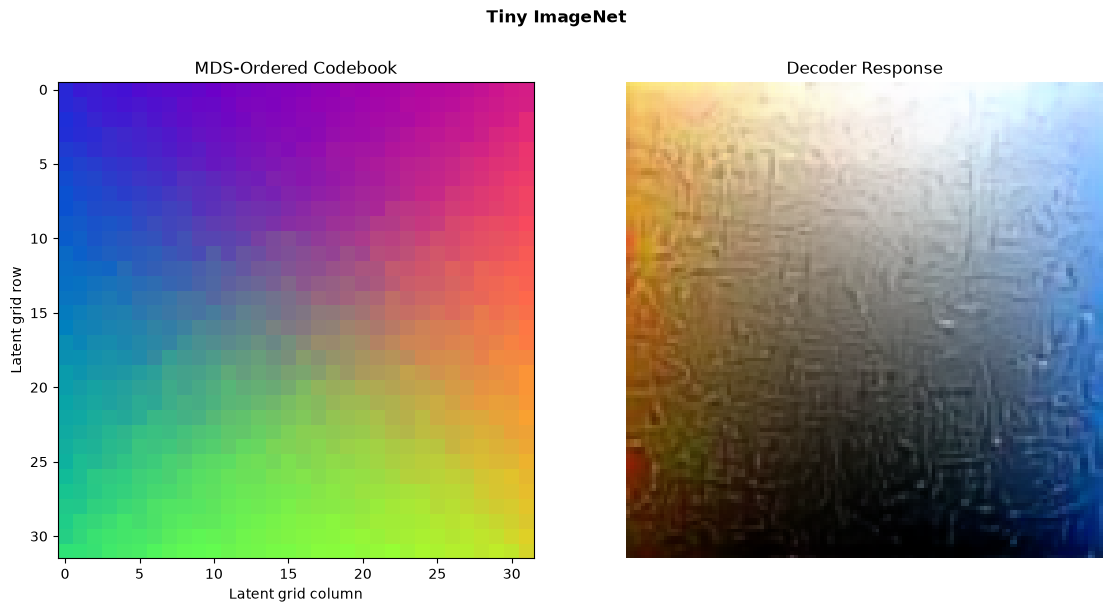

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 0. Load model
model = load_model(experiment_name, checkpoint, device)

model = model.to(device)
model.eval()

# 1. Get normalized AVQ codebook
with torch.no_grad():
    codebook = F.normalize(model.quantizer.codebook, dim=-1, eps=1e-6)

codebook_np = codebook.detach().cpu().numpy() # [1024, D]

# 2. Pairwise cosine distance: Since codebook vectors are normalized: cosine_distance(i, j) = 1 - dot(e_i, e_j)
similarity = np.clip(codebook_np @ codebook_np.T, -1.0, 1.0)

distance = 1.0 - similarity
np.fill_diagonal(distance, 0.0)
print("Distance matrix:", distance.shape)

# 3. Embed 1024 codewords into 2-D using MDS
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=42, normalized_stress="auto")

coords = mds.fit_transform(distance) # [1024, 2]

# 4. Normalize 2-D coordinates to [0, 1]
coords_norm = coords.copy()
coords_norm -= coords_norm.min(axis=0, keepdims=True)
coords_norm /= (coords_norm.max(axis=0, keepdims=True) + 1e-8)


# 5. Create target 32x32 grid positions
grid_y, grid_x = np.meshgrid(np.linspace(0.0, 1.0, 32), np.linspace(0.0, 1.0, 32), indexing="ij")

grid_points = np.stack([grid_x.ravel(), grid_y.ravel()], axis=1)
print("Grid points:", grid_points.shape) # [1024, 2]

# 6. One-to-one assignment of codewords to grid cells using Hungarian matching
cost = cdist(coords_norm, grid_points, metric="sqeuclidean")
code_indices, grid_indices = linear_sum_assignment(cost)

code_grid = np.empty(1024, dtype=np.int64)

for code_idx, grid_idx in zip(code_indices, grid_indices):
    code_grid[grid_idx] = code_idx

code_grid = code_grid.reshape(32, 32)

print("Code grid:", code_grid.shape)
print("Unique codes:", np.unique(code_grid).size)

# 7. Build latent tensor from ordered codebook and decode
decoded_img = decode_ordered_codebook(model, codebook, code_grid, decoder_grid_size=32)


# 8. Create a color visualization of codebook geometry: Nearby points in the 2-D embedding receive similar colors.
x = coords_norm[:, 0]
y = coords_norm[:, 1]

code_colors = np.stack([x, y, 1.0 - 0.5 * (x + y)], axis=-1)
code_colors = np.clip(code_colors, 0.0, 1.0)

# Arrange colors according to the actual 32 x 32 grid
color_grid = code_colors[code_grid]

# 9. Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(color_grid, interpolation="nearest")
axes[0].set_title("MDS-Ordered Codebook")
axes[0].set_xlabel("Latent grid column")
axes[0].set_ylabel("Latent grid row")

axes[1].imshow(decoded_img)
axes[1].set_title("Decoder Response")
axes[1].axis("off")

fig.suptitle("Tiny ImageNet", fontsize=12, fontweight="bold", y=0.98)

plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.94])
plt.savefig("avq_codebook_geometry_tiny_imagenet.pdf", bbox_inches="tight", pad_inches=0.03)
plt.show()